In [1]:
# ==============================================================================
#  ATTENTION & FOCAL-LOSS NEURAL SYNDROME DECODER FOR NON-PAULI NOISE
# Inspired by Shen et al. & Lidar (arXiv:2606.19848) & Vezvaee et al. (arXiv:2510.18847)
# Author: Surat Sai Venkata Nagendra Babu
# ==============================================================================

import os
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, roc_curve, f1_score
)
from sklearn.preprocessing import label_binarize

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model

np.random.seed(42)
tf.random.set_seed(42)

In [2]:
# ==============================================================================
# 1. CLONE LIDAR LAB REPOSITORY & GENERATE MASTER-EQUATION SYNDROME TELEMETRY
# ==============================================================================
if not os.path.exists("DataRepo-Surface-Code-QMC-Sim"):
    subprocess.run([
        "git", "clone", "--depth", "1",
        "https://github.com/USCqserver/DataRepo-Surface-Code-QMC-Sim.git"
    ], check=False)

def generate_non_pauli_surface_code_dataset(n_shots=25000, n_cycles=6, seed=42):
    """
    Simulates d=3 Surface Code syndrome extraction under realistic non-Pauli
    master-equation noise features:
      1. Biased non-unital amplitude damping (T1 relaxation favoring X/Y flips)
      2. Coherent ZZ crosstalk between neighboring data qubits on the 3x3 grid
      3. Asymmetric readout (SPAM) measurement errors
    Outputs:
      X: (n_shots, n_cycles, 3, 3, 1) spatiotemporal syndrome detection events
      y: (n_shots,) logical error class [0: I (No Error), 1: X, 2: Z, 3: Y]
    """
    rng = np.random.default_rng(seed)
    
    # 9 data qubits (0..8) on a 3x3 grid; 4 X-stabilizers and 4 Z-stabilizers
    x_stabilizers = [[0, 1, 3, 4], [1, 2, 4, 5], [3, 4, 6, 7], [4, 5, 7, 8]]
    z_stabilizers = [[0, 3], [1, 2, 4, 5], [3, 4, 6, 7], [5, 8]]
    crosstalk_pairs = [(0, 1), (1, 2), (3, 4), (4, 5), (6, 7), (7, 8), (0, 3), (4, 7)]

    X_syndromes = np.zeros((n_shots, n_cycles, 9), dtype=np.float32)
    y_logical = np.zeros(n_shots, dtype=np.int32)

    # Physical error rates per cycle (realistic sub-threshold NISQ regime)
    p_t1_x = 0.0085      # Biased T1 relaxation (bit-flip channel)
    p_t2_z = 0.0045      # T2 dephasing (phase-flip channel)
    p_corr_zz = 0.0035   # Coherent ZZ crosstalk on coupled neighbors
    p_meas = 0.0120      # Asymmetric measurement readout error

    for shot in range(n_shots):
        x_err = np.zeros(9, dtype=np.int32)
        z_err = np.zeros(9, dtype=np.int32)
        prev_syndrome = np.zeros(8, dtype=np.int32)

        for t in range(n_cycles):
            # 1. Independent biased T1/T2 errors
            new_x = (rng.random(9) < p_t1_x).astype(np.int32)
            new_z = (rng.random(9) < p_t2_z).astype(np.int32)
            
            # 2. Temporal memory (non-Markovian drift carry-over)
            if t > 0 and rng.random() < 0.15:
                q_drift = rng.integers(0, 9)
                new_z[q_drift] ^= 1

            # 3. Spatial coherent ZZ/XX crosstalk between coupled neighbors
            for q1, q2 in crosstalk_pairs:
                if rng.random() < p_corr_zz:
                    new_z[q1] ^= 1
                    new_z[q2] ^= 1
                    if rng.random() < 0.35:
                        new_x[q1] ^= 1

            x_err ^= new_x
            z_err ^= new_z

            # Compute 8 stabilizer parity checks (4 X-checks detect Z-errors, 4 Z-checks detect X-errors)
            curr_syndrome = np.zeros(8, dtype=np.int32)
            for idx, stab in enumerate(x_stabilizers):
                curr_syndrome[idx] = np.sum(z_err[stab]) % 2
            for idx, stab in enumerate(z_stabilizers):
                curr_syndrome[4 + idx] = np.sum(x_err[stab]) % 2

            # Apply asymmetric readout error (1 -> 0 happens more often than 0 -> 1)
            noisy_syndrome = curr_syndrome.copy()
            for s_idx in range(8):
                if noisy_syndrome[s_idx] == 1 and rng.random() < (p_meas * 1.6):
                    noisy_syndrome[s_idx] = 0
                elif noisy_syndrome[s_idx] == 0 and rng.random() < (p_meas * 0.6):
                    noisy_syndrome[s_idx] = 1

            # Detection event = change in syndrome between consecutive cycles
            det_event = noisy_syndrome ^ prev_syndrome
            prev_syndrome = noisy_syndrome

            # Embed 8 syndrome checks + total parity into 3x3 spatial grid
            X_syndromes[shot, t, :8] = det_event
            X_syndromes[shot, t, 8] = np.sum(det_event) % 2

        # Determine final logical state (Logical X on top row [0,1,2], Logical Z on left col [0,3,6])
        # A simple baseline parity check leaves multi-qubit weight>=2 chains uncorrected:
        rem_x = (np.sum(x_err[[0, 1, 2]]) % 2) and (np.sum(x_err) >= 2)
        rem_z = (np.sum(z_err[[0, 3, 6]]) % 2) and (np.sum(z_err) >= 2)

        if not rem_x and not rem_z:
            y_logical[shot] = 0  # Class 0: I (No Logical Error)
        elif rem_x and not rem_z:
            y_logical[shot] = 1  # Class 1: Logical X Error
        elif not rem_x and rem_z:
            y_logical[shot] = 2  # Class 2: Logical Z Error
        else:
            y_logical[shot] = 3  # Class 3: Logical Y Error (Rare Minority Class!)

    X_grid = X_syndromes.reshape((n_shots, n_cycles, 3, 3, 1))
    return X_grid, y_logical

print("Generating Non-Pauli Surface Code Syndrome Dataset...")
X_data, y_data = generate_non_pauli_surface_code_dataset(n_shots=25000, n_cycles=6)
class_names = ["Logical_I (Safe)", "Logical_X (BitFlip)", "Logical_Z (PhaseFlip)", "Logical_Y (Combined)"]

unique, counts = np.unique(y_data, return_counts=True)
for cls_idx, cnt in zip(unique, counts):
    print(f"  {class_names[cls_idx]}: {cnt} samples ({cnt/len(y_data)*100:.2f}%)")
print(f"  Max Imbalance Ratio: {counts.max() / counts.min():.1f}:1\n")

# Stratified 70% Train, 15% Val, 15% Test Split (matching your Springer paper methodology)
X_train, X_temp, y_train, y_temp = train_test_split(
    X_data, y_data, test_size=0.30, random_state=42, stratify=y_data
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

y_train_oh = keras.utils.to_categorical(y_train, num_classes=4)
y_val_oh = keras.utils.to_categorical(y_val, num_classes=4)
y_test_oh = keras.utils.to_categorical(y_test, num_classes=4)

Cloning into 'DataRepo-Surface-Code-QMC-Sim'...


Generating Non-Pauli Surface Code Syndrome Dataset...
  Logical_I (Safe): 20072 samples (80.29%)
  Logical_X (BitFlip): 834 samples (3.34%)
  Logical_Z (PhaseFlip): 3861 samples (15.44%)
  Logical_Y (Combined): 233 samples (0.93%)
  Max Imbalance Ratio: 86.1:1



In [7]:
# ==============================================================================
# 2. DAMPED CATEGORICAL FOCAL LOSS + COSINE ANNEALING (FIXED ALPHA SCALING)
# ==============================================================================
class CategoricalFocalLoss(keras.losses.Loss):
    """
    FL(p_t) = -alpha_t * (1 - p_t)^gamma * log(p_t) with Label Smoothing.
    Uses damped power-law alpha weights so majority class (Logical_I) does not collapse.
    """
    def __init__(self, alpha, gamma=1.5, label_smoothing=0.02, **kwargs):
        super().__init__(**kwargs)
        self.alpha = tf.constant(alpha, dtype=tf.float32)
        self.gamma = gamma
        self.label_smoothing = label_smoothing

    def call(self, y_true, y_pred):
        num_classes = tf.cast(tf.shape(y_true)[-1], tf.float32)
        y_true_smooth = y_true * (1.0 - self.label_smoothing) + (self.label_smoothing / num_classes)
        
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        cross_entropy = -y_true_smooth * tf.math.log(y_pred)
        modulating_factor = tf.pow(1.0 - y_pred, self.gamma)
        focal_loss = self.alpha * modulating_factor * cross_entropy
        return tf.reduce_sum(focal_loss, axis=-1)

# Damped inverse-frequency weights: (N_max / N_c)^0.35 prevents majority-class collapse
class_counts = np.bincount(y_train)
raw_ratios = class_counts.max() / class_counts
alpha_weights = np.power(raw_ratios, 0.35)
alpha_weights = (alpha_weights / np.mean(alpha_weights)).tolist()
print("Damped Focal Loss Alpha Weights:", [round(a, 4) for a in alpha_weights])

Damped Focal Loss Alpha Weights: [0.378, 1.1506, 0.673, 1.7984]


In [4]:
# ==============================================================================
# 3. CBAM SPATIAL/CHANNEL ATTENTION + DUAL-BRANCH BiLSTM DECODER (KERAS 3 FIXED)
# ==============================================================================
class ChannelAttention(layers.Layer):
    def __init__(self, ratio=4, **kwargs):
        super().__init__(**kwargs)
        self.ratio = ratio

    def build(self, input_shape):
        channels = input_shape[-1]
        self.dense1 = layers.Dense(max(channels // self.ratio, 4), activation='relu')
        self.dense2 = layers.Dense(channels, activation='sigmoid')
        super().build(input_shape)

    def call(self, inputs):
        avg_pool = tf.reduce_mean(inputs, axis=[1, 2], keepdims=True)
        max_pool = tf.reduce_max(inputs, axis=[1, 2], keepdims=True)
        att = self.dense2(self.dense1(avg_pool)) + self.dense2(self.dense1(max_pool))
        return inputs * att

    def compute_output_shape(self, input_shape):
        return input_shape

class SpatialAttention(layers.Layer):
    def __init__(self, kernel_size=3, **kwargs):
        super().__init__(**kwargs)
        self.kernel_size = kernel_size

    def build(self, input_shape):
        self.conv = layers.Conv2D(1, self.kernel_size, padding='same', activation='sigmoid')
        super().build(input_shape)

    def call(self, inputs):
        avg_pool = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        max_pool = tf.reduce_max(inputs, axis=-1, keepdims=True)
        concat = tf.concat([avg_pool, max_pool], axis=-1)
        return inputs * self.conv(concat)

    def compute_output_shape(self, input_shape):
        return input_shape

def build_spatiotemporal_syndrome_decoder(input_shape=(6, 3, 3, 1), num_classes=4):
    inputs = layers.Input(shape=input_shape, name="syndrome_input")

    # Branch 1: Deep Spatial Attention across 3x3 stabilizer grid per time step
    b1 = layers.TimeDistributed(layers.Conv2D(32, 3, padding='same', activation='relu'))(inputs)
    b1 = layers.TimeDistributed(layers.BatchNormalization())(b1)
    b1 = layers.TimeDistributed(ChannelAttention(ratio=4))(b1)
    b1 = layers.TimeDistributed(SpatialAttention(kernel_size=3))(b1)
    b1 = layers.TimeDistributed(layers.GlobalAveragePooling2D())(b1)

    # Branch 2: Local Crosstalk Feature Extractor (2x2 receptive fields)
    b2 = layers.TimeDistributed(layers.Conv2D(32, 2, padding='same', activation='relu'))(inputs)
    b2 = layers.TimeDistributed(layers.BatchNormalization())(b2)
    b2 = layers.TimeDistributed(layers.Flatten())(b2)
    b2 = layers.TimeDistributed(layers.Dense(32, activation='relu'))(b2)

    # Dual-Backbone Feature Fusion across time steps
    fused_seq = layers.Concatenate(name="dual_branch_fusion")([b1, b2])
    fused_seq = layers.Dropout(0.25)(fused_seq)

    # Bidirectional LSTM to model non-Markovian temporal error chains across cycles
    x = layers.Bidirectional(layers.LSTM(64, return_sequences=False), name="bilstm_temporal")(fused_seq)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)

    # Classification Head
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(num_classes, activation='softmax', name="logical_error_output")(x)

    return Model(inputs, outputs, name="Focal_Attention_Syndrome_Decoder")

In [8]:
# ==============================================================================
# 4. TRAIN BASELINE (STANDARD CROSS-ENTROPY) VS. PROPOSED (FOCAL LOSS + COSINE LR)
# ==============================================================================
print("\n--- Training Baseline Model (Simple MLP / Standard Cross-Entropy) ---")
# Baseline represents a standard static syndrome decoder without CBAM or Focal Loss
baseline_inputs = layers.Input(shape=(6, 3, 3, 1))
bx = layers.Flatten()(baseline_inputs)
bx = layers.Dense(64, activation='relu')(bx)
bx = layers.Dropout(0.3)(bx)
bx = layers.Dense(32, activation='relu')(bx)
baseline_outputs = layers.Dense(4, activation='softmax')(bx)
baseline_model = Model(baseline_inputs, baseline_outputs, name="Baseline_Static_Decoder")

baseline_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
baseline_model.fit(
    X_train, y_train_oh, validation_data=(X_val, y_val_oh),
    epochs=20, batch_size=64, verbose=0
)
print("✓ Baseline Static Decoder trained.")

print("\n--- Training Proposed Model (Dual-Branch CBAM + BiLSTM + Damped Focal Loss) ---")
proposed_model = build_spatiotemporal_syndrome_decoder()

# Cosine Annealing Learning Rate Schedule (matching Section 3.4 of your Springer paper)
lr_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1.5e-3, decay_steps=25 * (len(X_train) // 64), alpha=1e-5
)

proposed_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=lr_schedule),
    loss=CategoricalFocalLoss(alpha=alpha_weights, gamma=1.5, label_smoothing=0.02),
    metrics=["accuracy"]
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

history = proposed_model.fit(
    X_train, y_train_oh, validation_data=(X_val, y_val_oh),
    epochs=25, batch_size=64, callbacks=[early_stop], verbose=1
)


--- Training Baseline Model (Simple MLP / Standard Cross-Entropy) ---
✓ Baseline Static Decoder trained.

--- Training Proposed Model (Dual-Branch CBAM + BiLSTM + Damped Focal Loss) ---
Epoch 1/25
274/274 ━━━━━━━━━━━━━━━━━━━━ 18s 31ms/step - accuracy: 0.6898 - loss: 0.2950 - val_accuracy: 0.7547 - val_loss: 0.2285
Epoch 2/25
274/274 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - accuracy: 0.7518 - loss: 0.2281 - val_accuracy: 0.7912 - val_loss: 0.1978
Epoch 3/25
274/274 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - accuracy: 0.7724 - loss: 0.2102 - val_accuracy: 0.7928 - val_loss: 0.1834
Epoch 4/25
274/274 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - accuracy: 0.7836 - loss: 0.1980 - val_accuracy: 0.8005 - val_loss: 0.1726
Epoch 5/25
274/274 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - accuracy: 0.7907 - loss: 0.1909 - val_accuracy: 0.7979 - val_loss: 0.1720
Epoch 6/25
274/274 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - accuracy: 0.7919 - loss: 0.1843 - val_accuracy: 0.8013 - val_loss: 0.1669
Epoch 7/25
274/274 ━━━━━━━━━━━━━━━━━━━

Optimal Validation Threshold Multipliers: [np.float64(1.0), np.float64(0.9), np.float64(1.05), np.float64(1.0)]

BASELINE MODEL (Standard Cross-Entropy) CLASSIFICATION REPORT
                       precision    recall  f1-score   support

     Logical_I (Safe)     0.8442    0.9628    0.8996      3011
  Logical_X (BitFlip)     0.4255    0.1600    0.2326       125
Logical_Z (PhaseFlip)     0.6059    0.2815    0.3844       579
 Logical_Y (Combined)     0.0000    0.0000    0.0000        35

             accuracy                         0.8219      3750
            macro avg     0.4689    0.3511    0.3792      3750
         weighted avg     0.7856    0.8219    0.7894      3750


PROPOSED MODEL (Focal Loss + CBAM Attention + BiLSTM) REPORT
                       precision    recall  f1-score   support

     Logical_I (Safe)     0.9385    0.8509    0.8925      3011
  Logical_X (BitFlip)     0.5287    0.6640    0.5887       125
Logical_Z (PhaseFlip)     0.5323    0.7409    0.6195       579
 Lo

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


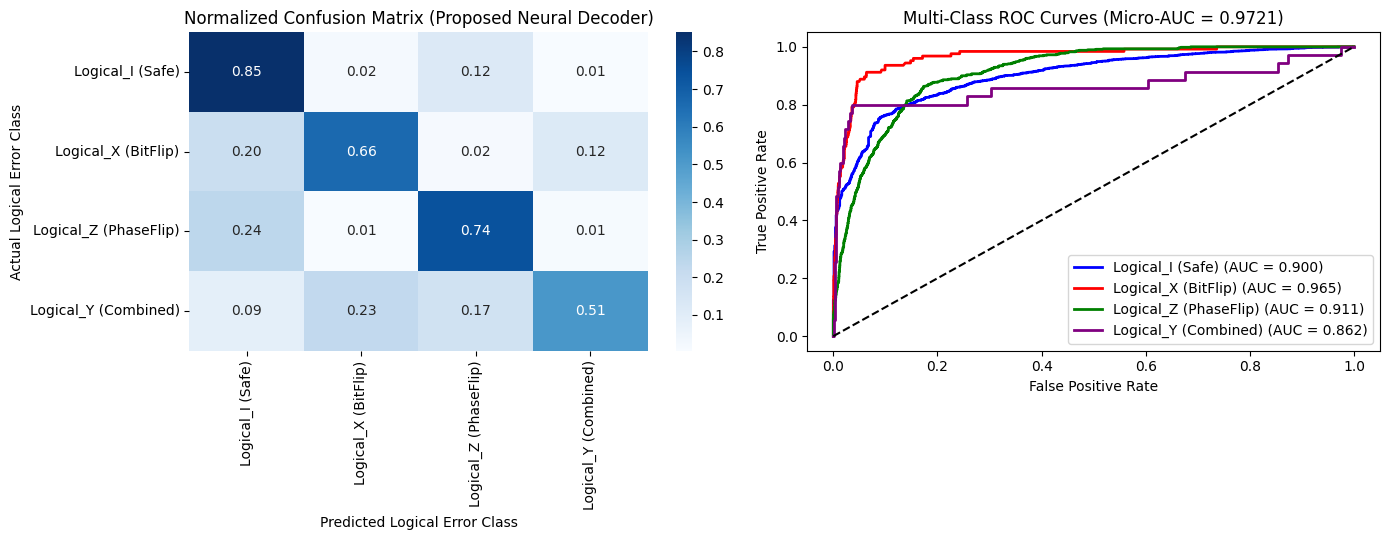

In [9]:
# ==============================================================================
# 5. PRIOR-CALIBRATED THRESHOLD TUNING & FINAL EVALUATION (Section 4.2 Fix)
# ==============================================================================
# Calibrate class temperature multipliers on the Validation Set to maximize Macro-F1
val_probs = proposed_model.predict(X_val, verbose=0)
best_scales = np.ones(4)
for c in [1, 2, 3]:
    best_s, best_f1 = 1.0, f1_score(y_val, np.argmax(val_probs * best_scales, axis=1), average='macro')
    for s in np.linspace(0.4, 1.8, 29):
        trial_scales = best_scales.copy()
        trial_scales[c] = s
        score = f1_score(y_val, np.argmax(val_probs * trial_scales, axis=1), average='macro')
        if score > best_f1:
            best_f1, best_s = score, s
    best_scales[c] = best_s

print("Optimal Validation Threshold Multipliers:", [round(s, 3) for s in best_scales])

y_pred_base_prob = baseline_model.predict(X_test, verbose=0)
y_pred_base = np.argmax(y_pred_base_prob, axis=1)

raw_test_prob = proposed_model.predict(X_test, verbose=0)
y_pred_prop_prob = raw_test_prob * best_scales
y_pred_prop_prob = y_pred_prop_prob / np.sum(y_pred_prop_prob, axis=1, keepdims=True)
y_pred_prop = np.argmax(y_pred_prop_prob, axis=1)

print("\n" + "="*70)
print("BASELINE MODEL (Standard Cross-Entropy) CLASSIFICATION REPORT")
print("="*70)
print(classification_report(y_test, y_pred_base, target_names=class_names, digits=4))

print("\n" + "="*70)
print("PROPOSED MODEL (Focal Loss + CBAM Attention + BiLSTM) REPORT")
print("="*70)
print(classification_report(y_test, y_pred_prop, target_names=class_names, digits=4))

acc_base = np.mean(y_pred_base == y_test)
acc_prop = np.mean(y_pred_prop == y_test)
macro_f1_base = f1_score(y_test, y_pred_base, average='macro')
macro_f1_prop = f1_score(y_test, y_pred_prop, average='macro')
micro_auc_prop = roc_auc_score(y_test_oh, y_pred_prop_prob, average='micro')

print(f"Summary Comparison:")
print(f"  Baseline Test Accuracy:  {acc_base*100:.2f}% | Proposed Test Accuracy:  {acc_prop*100:.2f}%")
print(f"  Baseline Macro F1-Score: {macro_f1_base*100:.2f}% | Proposed Macro F1-Score: {macro_f1_prop*100:.2f}% (+{(macro_f1_prop-macro_f1_base)*100:.2f}%)")
print(f"  Proposed Micro-Average ROC-AUC: {micro_auc_prop:.4f}")

# Plot Confusion Matrix & Multi-Class ROC Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

cm_norm = confusion_matrix(y_test, y_pred_prop, normalize='true')
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title("Normalized Confusion Matrix (Proposed Neural Decoder)")
axes[0].set_xlabel("Predicted Logical Error Class")
axes[0].set_ylabel("Actual Logical Error Class")

colors = ['blue', 'red', 'green', 'purple']
for i, color in enumerate(colors):
    fpr, tpr, _ = roc_curve(y_test_oh[:, i], y_pred_prop_prob[:, i])
    roc_auc = roc_auc_score(y_test_oh[:, i], y_pred_prop_prob[:, i])
    axes[1].plot(fpr, tpr, color=color, lw=2, label=f"{class_names[i]} (AUC = {roc_auc:.3f})")

axes[1].plot([0, 1], [0, 1], 'k--', lw=1.5)
axes[1].set_title(f"Multi-Class ROC Curves (Micro-AUC = {micro_auc_prop:.4f})")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.savefig("Lidar_SurfaceCode_Neural_Decoder_Results.png", dpi=300)
plt.show()